# 6 · Guía de trabajo en equipo — EDA automático con Sweetviz

> **¿Dónde estamos en el flujo del EDA?**
> En los notebooks 0 a 5 hicimos el EDA **a mano**: estructura, faltantes, descriptivos, histogramas, boxplots, relaciones y correlación.
> Ahora vamos a ver **librerías que generan un reporte exploratorio automático** con muy pocas líneas de código. Cubren varios pasos del flujo a la vez: **02 Conocer los datos**, **04 Evaluar la calidad** y **05 Explorar y analizar**.
>
> **Objetivo de esta guía:** no es solo "apretar un botón", sino **saber leer el reporte** y **verificar** que lo que dice coincide con lo que calculamos nosotros.

> **Pregunta guía del análisis (la misma de los notebooks 0 y 1):**
> ¿Qué características de las células parecen diferenciar un tumor **maligno** (`target = 0`) de uno **benigno** (`target = 1`)?

> **Cómo trabajar**
> 1. Hagan una copia del notebook (*Archivo → Guardar una copia en Drive*) y suban `sample_dataset.csv` al panel **Archivos** (ícono de carpeta, a la izquierda).
> 2. Ejecuten las celdas **en orden** (Shift + Enter).
> 3. Lean los cuadros 📘, completen las celdas 🧩 (reemplazar cada `COMPLETAR`) y respondan en las celdas ✍️.
>    Las celdas 🧩 **dan error hasta que reemplacen `COMPLETAR`**: es esperable, no es un problema del notebook.
> 4. Al final, armen la sección 🎤: **cada equipo va a explicar su notebook al resto del curso en 5 minutos.**
>
> | Ícono | Significa |
> |---|---|
> | 📘 | Concepto (relacionado con la teoría vista) |
> | 💻 | Código listo para ejecutar y observar |
> | 🧩 | Código para completar (reemplazar `COMPLETAR`) |
> | ✍️ | Pregunta para responder en equipo |
> | ⭐ | Extra, solo si les sobra tiempo |
> | 🎤 | Lo que van a presentar al resto |

## 1) ¿Qué es un reporte automático de EDA?

📘 **Concepto.** Son librerías que, a partir de un DataFrame, calculan y grafican automáticamente lo que veníamos haciendo a mano y lo presentan como una **página HTML interactiva**.

| Ventajas | Riesgos / límites |
|---|---|
| Muy rápido: una primera mirada en segundos | **No reemplaza el criterio del analista**: no sabe qué significa cada variable ni cuál es la pregunta |
| Detecta problemas que se nos pueden pasar (faltantes, duplicados, constantes) | Puede marcar como "problema" algo que no lo es (o al revés) |
| Bueno para compartir con otros | Con muchos datos puede ser lento y pesado |

> **Regla de oro:** el reporte automático es un **punto de partida**. Las conclusiones las escribe el analista, y los números importantes se **verifican**.

VAMOS A VER ALGUNAS LIBRERÍAS QUE FACILITAN EL ANÁLISIS EXPLORATORIO CON TAN SOLO UNAS LÍNEAS DE CÓDIGO. En esta guía: **Sweetviz**.

## 2) Instalación

💻 Sweetviz es incompatible con NumPy 2.x (la versión que trae Colab), así que instalamos una versión anterior de NumPy.

> ⚠️ **Muy importante:** después de ejecutar esta celda, Colab puede mostrar un aviso **"Restart session"** (reiniciar sesión).
> Hagan clic en **Reiniciar sesión** (o *Entorno de ejecución → Reiniciar sesión*) y **sigan desde la celda siguiente** (no vuelvan a ejecutar esta).
> Si después aparece un error del tipo `numpy.dtype size changed` o `VisibleDeprecationWarning`, es que no se reinició la sesión.

In [ ]:
#!pip install sweetviz
!pip install numpy==1.26.4
!pip install sweetviz --upgrade

In [ ]:
import sweetviz
import pandas as pd
import numpy as np

In [ ]:
# Cada notebook es independiente: hay que volver a importar librerías y cargar los datos.
# Si aparece FileNotFoundError: el CSV no está subido en el panel "Archivos" de ESTE notebook.
df = pd.read_csv("sample_dataset.csv")
df.shape   # esperamos (569, 31)

## 3) Generar el reporte

💻 Lo primero que hacemos es crear un objeto que contenga los cálculos realizados por la librería Sweetviz.

- `analyze(df)` analiza **todas** las columnas.
- `target_feat="target"` le indica cuál es la **variable objetivo**: así el reporte muestra cómo se relaciona cada variable con el diagnóstico (nuestra pregunta guía).

In [ ]:
report = sweetviz.analyze(df, target_feat="target")

Esta instrucción le dice a Sweetviz que analice el DataFrame y genere un informe exploratorio automático.

Una vez que los cálculos fueron realizados, podemos mostrarlos de dos maneras:
- `show_html()` → genera un archivo **HTML** (lo encuentran en el panel *Archivos* como `SWEETVIZ_REPORT.html`; se descarga y se abre en el navegador).
- `show_notebook()` → lo muestra **dentro** del notebook.

In [ ]:
report.show_html(layout="vertical")

In [ ]:
report.show_notebook()
#-Nos va a permitir ver una descripción gral del df :
#cantidad de filas
#valores duplicados
#qué tan pesado es el conjunto de datos
# la cantidad de variables
#cuántas variables categóricas tenemos
#cuántas numéricas
#cuántas de texto, etc
#Luego se ve el histograma de la variable target , para los valores 0 y 1, con la cantidad de valores totales, los missing y los distintos. Si hacemos click sobre la palabra target
#vemos que se expande una vista, con el top de las categorías, aquellas variables categóricas que aportan información a la variable target, viceversa,
#y los valores de correlación respecto al resto de las variables.

## 4) 🔎 Búsqueda guiada en el reporte

📘 **Cómo se lee el reporte de Sweetviz:**
- **Arriba:** resumen general (filas, duplicados, tamaño en memoria, cuántas variables de cada tipo).
- **Una "tarjeta" por variable:** cantidad de valores, faltantes (*MISSING*), distintos (*DISTINCT*), estadísticas y un **histograma**. La línea superpuesta en el histograma muestra el **promedio del target** en cada intervalo.
- **Al hacer clic en una tarjeta** se despliegan más detalles: percentiles, asimetría (*skewness*) y **asociaciones** con las demás variables.
- **Botón *ASSOCIATIONS*** (arriba): el mapa de asociaciones entre todas las variables.

✍️ Respondan **usando solo el reporte** (todavía sin código):
1. ¿Cuántas filas y cuántas filas **duplicadas** informa?
2. ¿Cuántas variables reconoce como **numéricas** y cuántas como **categóricas**? ¿`target` y `area error` las clasifica bien?
3. ¿Qué porcentaje de **faltantes** tiene `mean smoothness`?
4. En la tarjeta de `mean radius`: ¿qué forma tiene el histograma? ¿Qué pasa con la línea del target a medida que crece el radio?

✍️ **Respuesta del equipo:**

_(Doble clic acá para escribir la respuesta.)_

🧩 **Verifiquemos con pandas.** Completen el código para comprobar dos de los números que leyeron en el reporte (lo vimos en el notebook 0).

In [ ]:
# % de faltantes de mean smoothness
print("Faltantes mean smoothness (%):", round(df["mean smoothness"].isna().mean() * 100, 1))

# cantidad de filas duplicadas
print("Filas duplicadas:", df.duplicated().sum())

✍️ **Pregunta:** ¿Coinciden los números del reporte con los de pandas? ¿Por qué es buena práctica verificar al menos los números más importantes?

✍️ **Respuesta del equipo:**

_(Doble clic acá para escribir la respuesta.)_

## 5) Asociaciones

Otra herramienta interesante es el **Association Heatmap** (botón *ASSOCIATIONS* en la parte superior del reporte):

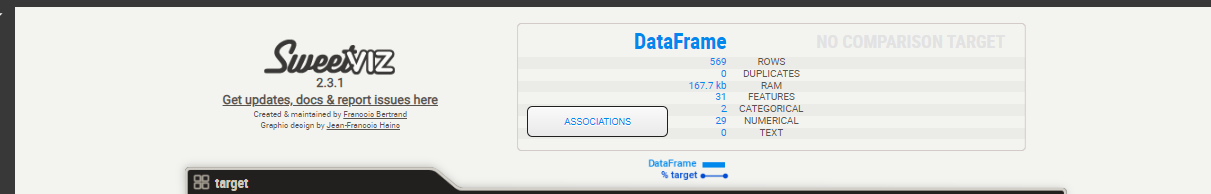

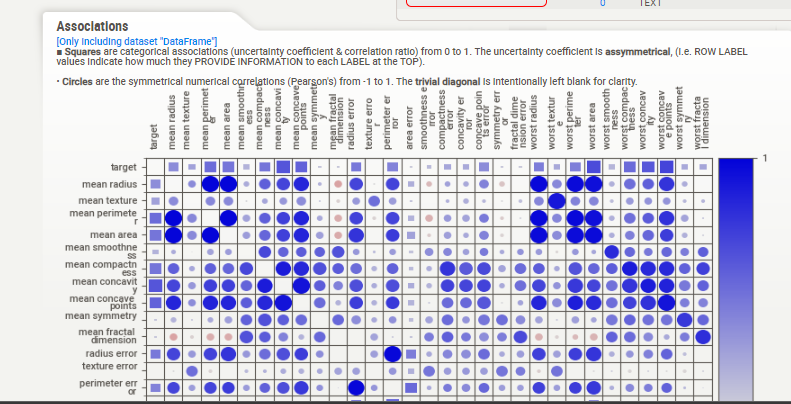

Los cuadrados y redondeles representan la intensidad de la correlación.
La variable categórica se representa mediante el **cuadrado**.
El **círculo** representa la correlación numérica entre las variables.

📘 **Concepto.** Es una versión ampliada del heatmap del notebook 5. Como mezcla variables numéricas y categóricas, usa distintas medidas de asociación:
- **numérica ↔ numérica** → correlación de Pearson (círculos), de -1 a 1;
- **categórica ↔ numérica** → *correlation ratio* (cuadrados), de 0 a 1;
- **categórica ↔ categórica** → *uncertainty coefficient* (cuadrados), de 0 a 1.

Cuanto **más grande y más intenso** el símbolo, **más fuerte** la asociación.

✍️ **Preguntas**
1. En el mapa del reporte de ustedes, ¿qué variables tienen la asociación más fuerte con `target`?
2. ¿Encuentran las mismas "familias" de variables muy correlacionadas que en el heatmap del notebook 5 (tamaño: radius/perimeter/area; concavidad)?

✍️ **Respuesta del equipo:**

_(Doble clic acá para escribir la respuesta.)_

## 6) Comparar dos conjuntos de datos

Otra interesante funcionalidad que tiene la librería es la de **comparar dos conjuntos de datos entre sí**.

📘 Sirve, por ejemplo, para comparar datos de **dos períodos**, **entrenamiento vs. prueba** de un modelo, o **dos grupos** (malignos vs. benignos).

In [ ]:
report2 = sweetviz.compare([df.head(50),"Dataset 1"],[df.tail(50),"Dataset 2"],target_feat="target")
report2.show_notebook(layout="vertical")
#Ahora tenemos la misma dinámica, pero la comparativa por colores indica los datos del conjunto 1 (azul) vs el conjunto 2 (naranja)

In [ ]:
report2.show_notebook()

✍️ **Pregunta:** Comparamos las **primeras 50** filas con las **últimas 50**. ¿Las distribuciones se parecen? Miren el target de cada conjunto: ¿qué nos dice esto sobre **cómo está ordenado** el dataset? ¿Qué riesgo tendría analizar solo con `head()`?

✍️ **Respuesta del equipo:**

_(Doble clic acá para escribir la respuesta.)_

🧩 **Tu turno: comparar malignos vs. benignos.** `compare_intra()` compara dos grupos **dentro del mismo DataFrame**, según una condición True/False. Completen la condición para que el primer grupo sean los **malignos**.

In [ ]:
report3 = sweetviz.compare_intra(df, df["target"] == 0, ["Maligno", "Benigno"])
report3.show_notebook(layout="vertical")